**Universidad Católica "Nuestra Señora de la Asunción"**

**Facultad de Ciencias y Tecnología**

###**Telecomunicaciones 1**
---



#**Memoryless nonlinear modulation: Sistemas de Modulación Digital sin Memoria**

---

**Contenido:**
1. Modulación PAM
2. Modulación PSK
3. Modulación QAM

**Objetivos:**
1. Aprender a programar moduladores digitales sin memoria
2. Describir mediante gráficos el espectro de señales moduladas
3. Comprender y verificar las ventajas y deventajas de los esquemas programados

---

## **1. Modulación PAM**




### **1a. PAM Banda Base**


$s_m(t)=A_m\,p(t)$ para  $m=\pm 1, \pm 3,...,\pm M-1$


Am = [-3 -1  1  3]
Secuencia aleatoria I = [0 0 0 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 1 1 0 0 0
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 1 1 0 1 1 1 1 1 0 1 1 0 0 1 0 1 0 0 1 1 1
 1 0 0 0 1 1 1 0 0 1 0 1 0 1 0 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 0 1 0 1 0 0 1
 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 1
 0 1 1 0 1 0 1 1 1 0 0 1 1 1 1 0 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1
 0 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0
 0 0 1 1 1 0 1 0 1 0 1 0 1 0 0 1 1 1 0 0 1 1 1 0 0 1 0 0 1 1 1 0 1 0]
Símbolos PAM: [0 0 0 1 0 0 3 2 0 2 0 1 3 0 1 2 3 0 1 0 0 1 0 0 2 1 1 2 3 3 2 3 0 2 2 1 3
 2 0 3 2 1 1 1 0 3 0 3 1 1 3 2 1 1 0 2 0 0 2 2 0 2 3 2 2 3 0 2 0 2 2 1 1 1
 1 2 2 3 2 1 3 2 1 1 0 3 0 0 1 0 0 1 2 3 2 0 1 3 3 0 2 1 3 0 3 1 0 2 0 3 0
 0 3 2 2 2 2 2 1 3 0 3 2 1 0 3 2 2]


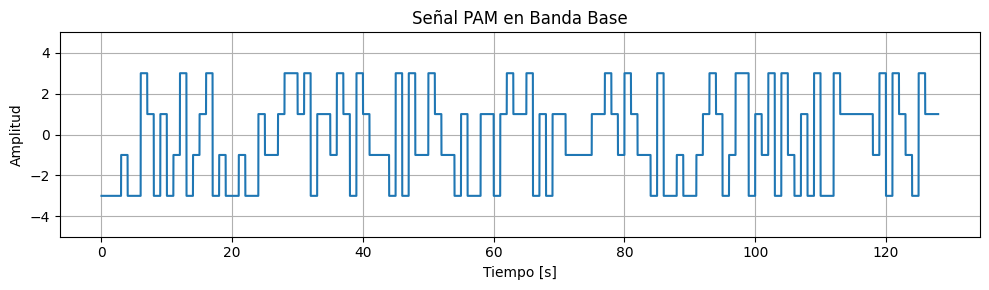

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Parámetros
T = 1                 # Tiempo por símbolo
M = 4                 # Número de niveles PAM
k = int(math.log2(M)) # Bits por símbolo
L = 2**8              # Longitud total de bits (múltiplo de k)
Ts = 0.01             # Tiempo de muestreo
fs = 1 / Ts           # Frecuencia de muestreo

# Amplitudes PAM
Am = np.arange(-M+1, M, 2)
print("Am =", Am)

# Generar bits aleatorios
I = np.random.randint(0, 2, L)
print("Secuencia aleatoria I =", I)

# Convertir bits a símbolos
symbols = np.zeros(L // k, dtype=int)
for i in range(len(symbols)):
    for j in range(k):
        symbols[i] += I[i * k + j] * 2**(k - j - 1)

print("Símbolos PAM:", symbols)

# Generar s(t)
t_total = T * len(symbols)
tt = np.arange(0, t_total, Ts)
s = np.zeros_like(tt)

for i, symb in enumerate(symbols):
    idx_start = int(i * T / Ts)
    idx_end = int((i + 1) * T / Ts)
    s[idx_start:idx_end] = Am[symb]

# Graficar s(t)
plt.figure(figsize=(10, 3))
plt.plot(tt, s, label='s(t)')
plt.title("Señal PAM en Banda Base")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.ylim([-5, 5])
plt.tight_layout()
plt.show()


### **1b. PAM Pasobanda**

$s_{m-bp}(t)=A_m\,p(t)=A_m\,g(t)cos(2\pi f_c t)$ para  $m=\pm 1, \pm 3,...,\pm M-1$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
fc = 1  # Frecuencia de la portadora (Hz)

# Señal portadora
carrier = np.cos(2 * np.pi * fc * tt)

# Señal paso banda
s_bp = s * carrier



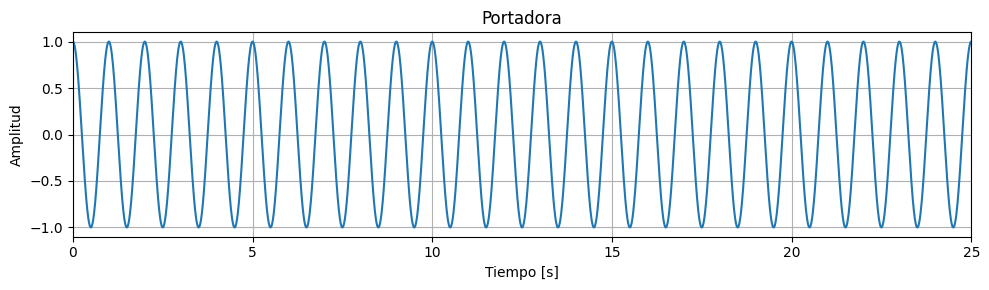

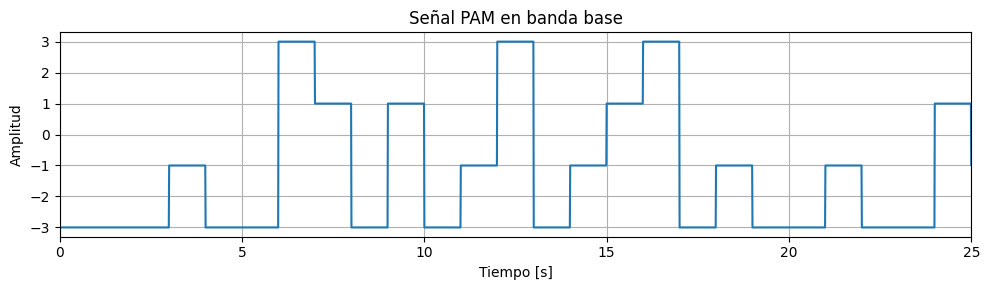

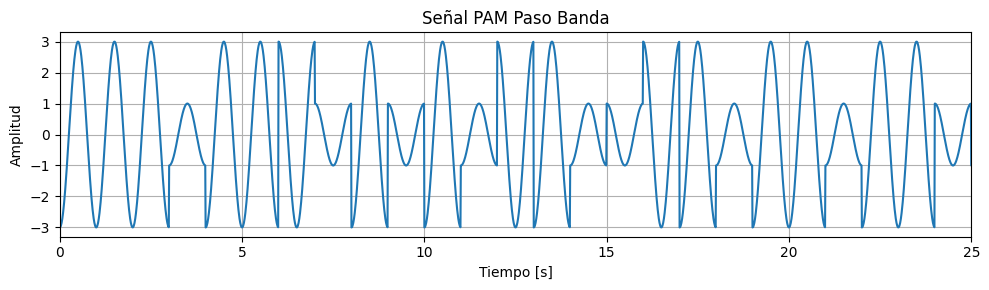

In [ ]:
# Graficar c(t), s(t), s_bp(t)
plt.figure(figsize=(10, 3))
plt.plot(tt, carrier, label='Portadora $c(t)$')
plt.title("Portadora")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.xlim([0, 25])
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(tt, s, label='Banda base $s(t)$')
plt.title("Señal PAM en banda base")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.xlim([0, 25])
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(tt, s_bp, label='Paso banda $s_{BP}(t)$')
plt.title("Señal PAM Paso Banda")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.xlim([0, 25])
plt.grid(True)
plt.tight_layout()
plt.show()


### **1c. PAM Espectro**


#### **Mal hecho con FFT**


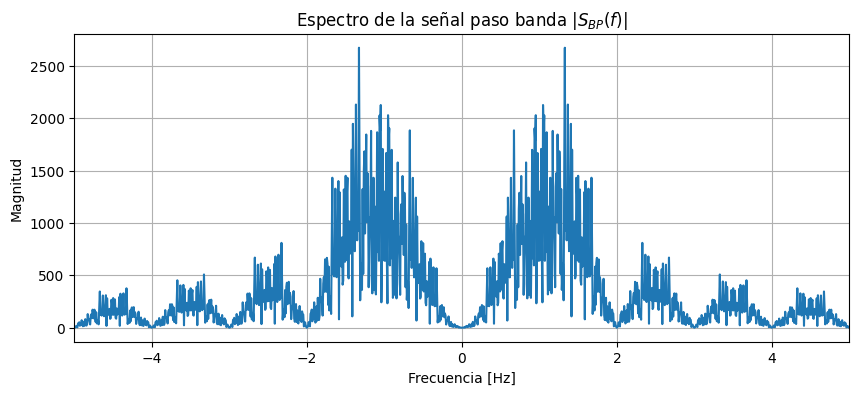

In [ ]:

S_f_numeric = np.fft.fftshift(np.fft.fft(s_bp))
freqs = np.fft.fftshift(np.fft.fftfreq(len(tt), d=1 / Fs))

# Graficar el espectro de la señal paso banda (magnitud)
plt.figure(figsize=(10, 4))
plt.plot(freqs, np.abs(S_f_numeric))
plt.title("Espectro de la señal paso banda $|S_{BP}(f)|$")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.grid(True)
plt.xlim([-5, 5])  # Puedes ajustar este límite según necesidad
plt.show()

#### **Con Welch**


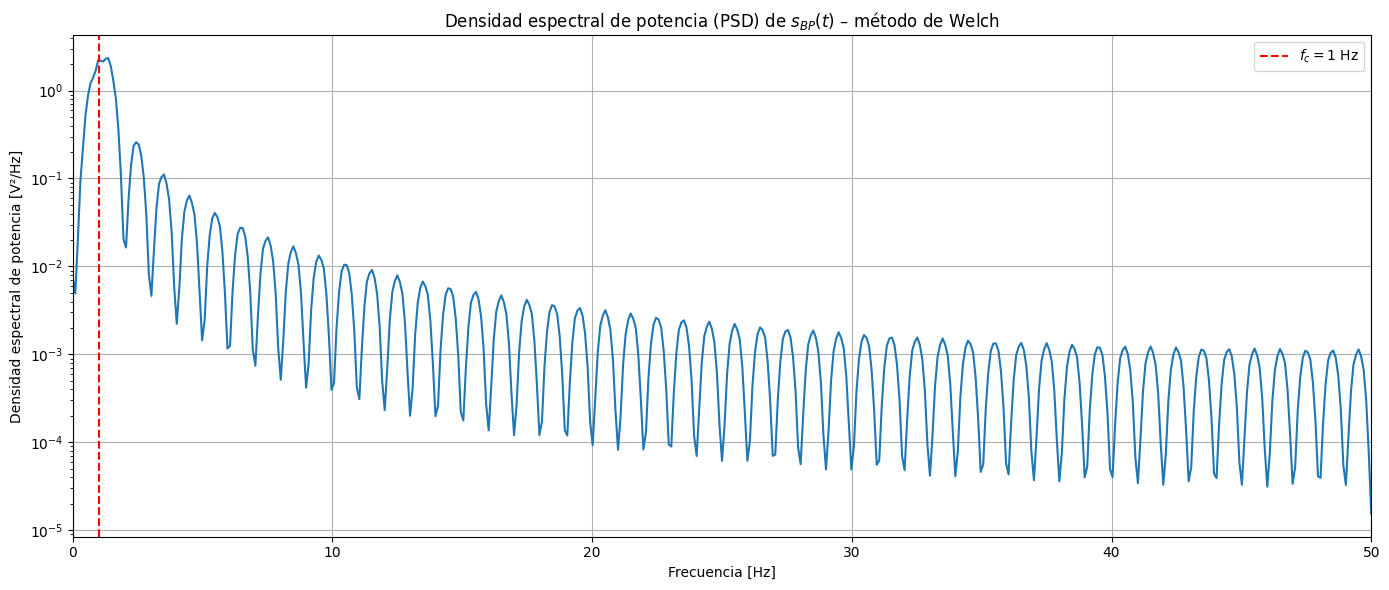

In [ ]:
from scipy.signal import welch

# Calcular la PSD con Welch
f_welch, Pxx_welch = welch(s_bp, fs=fs, nperseg=1024, scaling='density')


# Graficar el espectro (PSD)
plt.figure(figsize=(14, 6))
plt.semilogy(f_welch, Pxx_welch)
plt.xlim([0, fs / 2])  # Hasta Nyquist
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.title("Densidad espectral de potencia (PSD) de $s_{BP}(t)$ – método de Welch")
plt.grid(True)
plt.axvline(fc, color='r', linestyle='--', label=f'$f_c = {fc}$ Hz')
plt.legend()
plt.tight_layout()
plt.show()


---

## **2. Modulación PSK**


### **2a. PSK paso-banda**


$s_m(t)=g(t)\cos(2\pi f_c t + \theta_m)$ para  $\theta_m= 2\pi (m-1)/M$

Secuencia de entrada: [np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np

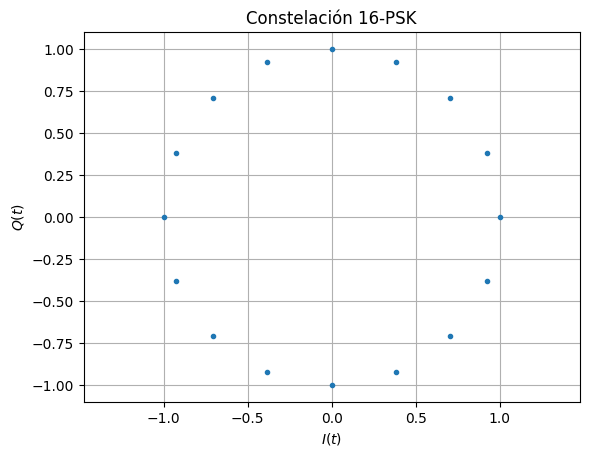

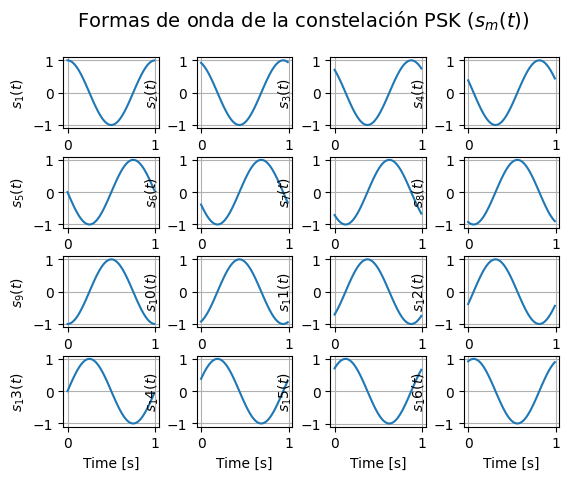

Símbolos a transmitir: [ 3  9  8  2  1  2 13 12  1  7  3  9  1  2 11  0  6  1 12 12 12 13  5 15
  5  9  4  0  9 10 12  2 12  0  0  4 14 11  4  0  2  9 12 10  3  8  3  7
 13  0  7 13  9  1  8  9 14 13  1 10  9  6  2 13  2 15  8 12 10  9 13  2
  3  5 15  6 11 13 15  8  7 12  7  5  1 12 12  8  8 10  5  0  1  0  3  8
  4  1  8  3 13  8  9 11  0 11  7  9  2 12 14  2  9  4 13 14 10  7 11  2
  2  6 11  4  9 13  3 12 14  4 12  0  5 10  1 14  1  3 10  4  3  7  5  9
 12 10 14  6 14 11  1  7  2  8 10 14  6  8 15 11  2 14  0  1 12  8  7 14
  2 12  5  0  8  8  9 14 10  3  8  0 15  7 11  1  1  6  3  5 14  2  6  8
  1  3 14  4  8 13 12 13  3  5 10 11  0  9  1  3 12  9 10  1  4 10  8 12
  9  5 12 12  5  3  6  1 10 13 12 14 13  7  3  9  7 13 10 12 13  7  8  7
 15 14  3  3  7 14 11  0  0  4  3  4 13  8  6 12]
Fases transmitidas: [ 67.5 202.5 180.   45.   22.5  45.  292.5 270.   22.5 157.5  67.5 202.5
  22.5  45.  247.5   0.  135.   22.5 270.  270.  270.  292.5 112.5 337.5
 112.5 202.5  90.    0.  202.5 

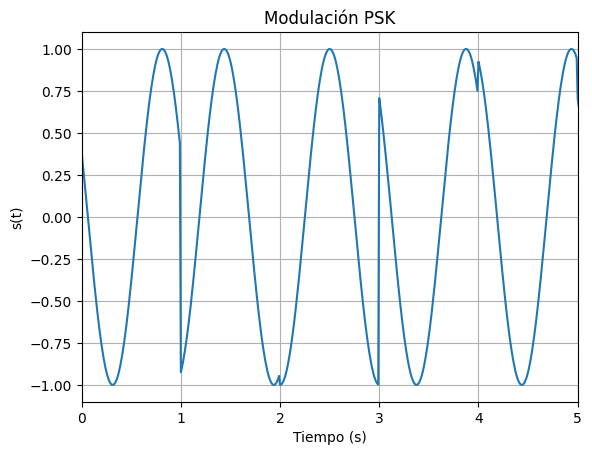

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Secuencia binaria de entrada (debe ser múltiplo de k)
#I = [0,0,0,1,1,0,1,1,0,1,1,0,1,0,1,0]
I=[0,0,0,1,1,0,1,1,0,1,0,1,1,0,1,0]   #Debe ser multiplo de k= log2 M
L = 2**10  # Longitud deseada para la secuencia de bits (debe ser múltiplo de k)

# Verificación
if L % k != 0:
    raise ValueError("L debe ser un múltiplo de k = log2(M)")

# Generar secuencia de bits aleatoria
I = list(np.random.randint(0, 2, L))
print("Secuencia de entrada:", I)

# Parámetros
M = 16 # Número de fases/símbolos
Ts = 0.01 # Tiempo de muestreo
k = int(math.log(M, 2)) # Cantidad de bits por símbolo
print("k =", k)
print("Bits de entrada:", len(I))

Tsym = 1 # Tiempo por símbolo
Tsim = len(I)/k * Tsym # Tiempo total de simulación
fc = 1 # Frecuencia de portadora

# Tiempo total y por símbolo
t = np.arange(0, Tsim, Ts)
tsym = np.arange(0, Tsym, Ts)

# Pulso rectangular (opcional para otras modulaciones)
g = np.ones(int(Tsim/Ts))

# Fases posibles
theta = np.arange(0, 2*np.pi, 2*np.pi/M)
print("Fases =", theta)

# Coordenadas I/Q de la constelación
s_I = []
s_Q = []
for i in range(M):
    s_I.append(np.cos(theta[i]))
    s_Q.append(np.sin(theta[i]))

# Gráfico de constelación
plt.plot(s_I, s_Q, '.')
plt.xlabel('$I(t)$')
plt.ylabel('$Q(t)$')
plt.title("Constelación " + str(M) + "-PSK")
plt.grid(True)
plt.axis("equal")
plt.show()

# Graficar formas de onda s_i(t) para cada símbolo
for i in range(1, M+1):
    plt.subplot(round(np.sqrt(M)), round(np.sqrt(M)), i)
    plt.plot(tsym, np.cos(2*np.pi*fc*tsym + theta[i-1]))
    plt.xlabel('Time [s]')
    plt.ylabel('$s_'+str(i)+'(t)$')
    plt.grid(True)
plt.subplots_adjust(hspace=0.4, wspace=0.4)
plt.suptitle('Formas de onda de la constelación PSK ($s_m(t)$)', fontsize=14)
plt.show()

# --------------------------------------------------------
# Asignación de símbolos según bits
symbols = np.zeros(int(len(I)/k), dtype=int)
for i in range(len(symbols)):
    for j in range(k):
        symbols[i] += I[i*k + j] * int(math.pow(2, j))

print("Símbolos a transmitir:", symbols)

# Generar señal s(t)
s = []
theta_TX = np.zeros(len(symbols))
for i in range(len(symbols)):
    theta_TX[i] = theta[symbols[i]]
    s = np.append(s, np.cos(2 * np.pi * fc * tsym + theta[symbols[i]]))

print("Fases transmitidas:", np.rad2deg(theta_TX))

# Graficar s(t)
plt.plot(t, s)
plt.title("Modulación PSK")
plt.xlabel("Tiempo (s)")
plt.ylabel("s(t)")
plt.xlim([0, 5])
plt.grid(True)
plt.show()

### **2b. PSK Spectrum**

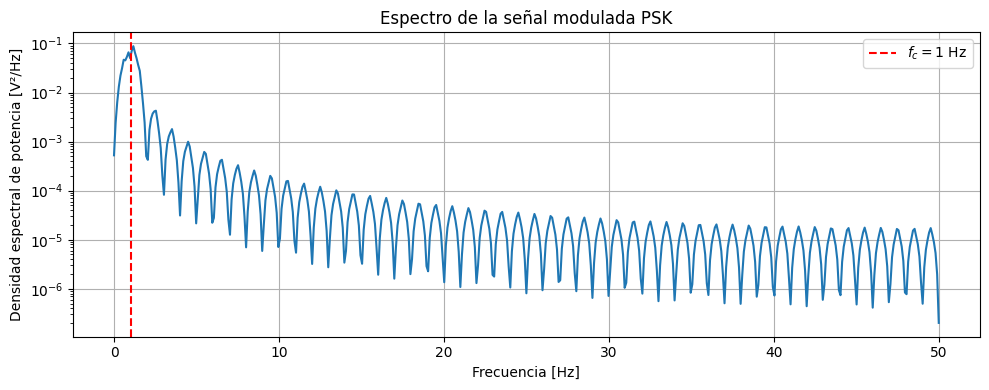

In [ ]:
from scipy.signal import welch

# Asegurar que s es un vector 1D
s = np.real(np.array(s).flatten())
s = np.array(s).flatten()

# Frecuencia de muestreo
Fs = 1 / Ts

# Welch
nperseg = 1024
freqs, Pxx = welch(s, fs=Fs, nperseg=nperseg, scaling='spectrum')

# Graficar
plt.figure(figsize=(10, 4))
plt.semilogy(freqs, Pxx)
plt.title("Espectro de la señal modulada PSK")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.grid(True)
plt.axvline(fc, color='r', linestyle='--', label=f'$f_c = {fc}$ Hz')
plt.legend()
#plt.xlim([0, 5 * fc])
plt.tight_layout()
plt.show()


---

## **3. Modulación QAM**


###**3a. QAM paso-banda**
---

Bits de entrada: [0 0 1 1 0 0 1 0 0 1 1 1 0 0 1 0 1 1 0 0 1 1 1 0 1 1 0 0 1 1 1 1 0 1 0 1 1
 1 0 0 0 1 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 1 0
 1 1 1 0 0 0 1 1 0 1 1 0 1 1 0 0 0 1 1 0 1 1 1 1 0 0 0 0 1 0 1 1 0 1 0 1 1
 0 0 1 0 1 1 1 1 1 1 0 0 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 0
 1 0 1 1 1 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 0 0 0 1 0 0 1
 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 0 1 1 1 0 1 1 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1
 1 0 1 1 0 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 1 1 1 1 0 1 0 0 1 1 0 0
 0 1 1 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1 0 1
 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 0 1 1 0 1 0 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1
 0 1 0 0 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 1
 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 1
 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1
 1 1 1 1 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 1 1 0 1 1
 0 0 0 1

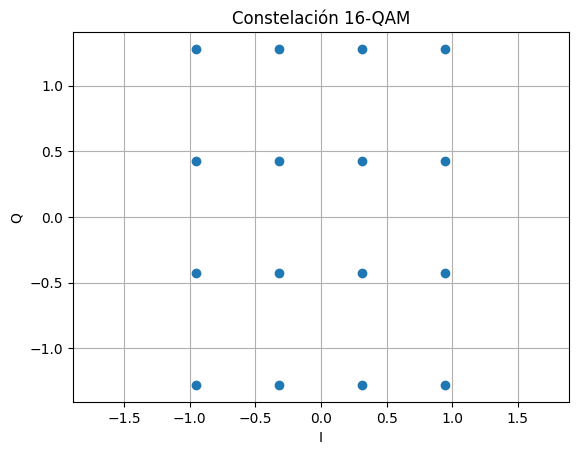

Simbolos: [12  4 14  4  3  7  3 15 10  3  2  4  6 12 10 14 10  6 13  1 11 13  8 13
  3  4 11  6 10 15  1 12 13 12  1  2  0 13  9  2  1  1 11 13  2  2  1  8
  4  9 14  6  0  4  5  7  3  5  4  2  0 10  7  9  1  3  2  8  7  6  6  2
  5 10  8 13  6  3 11  6  9  4  1  5 10  8 15  3  4  4  3  0 14  1 15  6
  6  7  1  3 13  7  9  4 14 13  6  7  7 10 12 15 12  0  7  0  4 10 10 11
  1 13  6 11  7  2 13  4  9 15  0 12 14 14  7  2 12 13  2  1  3 11  8  9
 14  5 11 10 11  6  2 10  7  6 12  1  6  3 14 10 10  6  4 12 12  5 10  1
  7  4 14  1  5 12  1  7  4 15  0  9  3  3  6  4  7  9  2 13 10  4  3  2
  7  9  8  3  6 15 14  9 13  1  7 15 14 14  9 13  2 11  5 11 13 10 10  7
  1 13  9  3  8 11  6  8  4  8  4 12  0  5 12  8  8 11  1 12  6 15 11 14
  4  0 15  0  2 14  1  5  8 14  2  2  6  5  2  0]


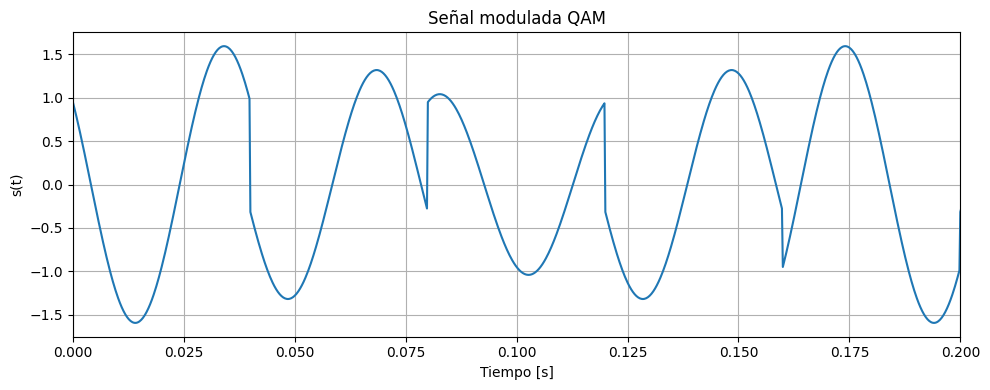

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Parámetros
M = 16  # Tamaño de constelación (debe ser cuadrado perfecto para QAM)

k = int(math.log2(M))  # Cantidad de bits por símbolo
L = 2**10  # Longitud de la secuencia de bits (múltiplo de k)
fc = 25  # Frecuencia de portadora
Tsym = 1/fc  # Duración de cada símbolo
Ts = 1/(200*fc)  # Tiempo de muestreo
# Verificación
if L % k != 0:
    raise ValueError("L debe ser múltiplo de k")

# Secuencia binaria aleatoria
I_bits = np.random.randint(0, 2, L)
# Configuración para no truncar la impresión
np.set_printoptions(threshold=np.inf)
print("Bits de entrada:", I_bits)

# Tiempo total
Ns = int(L / k)  # Número de símbolos
Tsim = Ns * Tsym  # Tiempo total
t = np.arange(0, Tsim, Ts)
tsym = np.arange(0, Tsym, Ts)  # Tiempo para un símbolo

# Constelación QAM (rectangular)
sqrt_M = int(np.sqrt(M))
amps = np.arange(-sqrt_M + 1, sqrt_M, 2)  # e.g. [-3, -1, 1, 3] para 16-QAM
I_const = np.repeat(amps, sqrt_M)
Q_const = np.tile(amps[::-1], sqrt_M)

# Normalizamos la energía promedio
I_const = I_const / np.sqrt((I_const**2 + Q_const**2).mean())
Q_const = Q_const / np.sqrt((I_const**2 + Q_const**2).mean())

# Mostrar constelación
plt.figure()
plt.scatter(I_const, Q_const)
plt.grid(True)
plt.title(f"Constelación {M}-QAM")
plt.xlabel("I")
plt.ylabel("Q")
plt.axis("equal")
plt.show()

# Mapear bits a símbolos
symbols = np.zeros(Ns, dtype=int)
for i in range(Ns):
    for j in range(k):
        symbols[i] += I_bits[i * k + j] << j  # bits a entero
print("Simbolos:", symbols)
# Generar la señal QAM s(t)
s = []
for i in range(Ns):
    i_comp = I_const[symbols[i]]
    q_comp = Q_const[symbols[i]]
    s_i = i_comp * np.cos(2 * np.pi * fc * tsym) - q_comp * np.sin(2 * np.pi * fc * tsym)
    s.extend(s_i)

s = np.array(s)

# Graficar señal QAM en el tiempo
plt.figure(figsize=(10, 4))
plt.plot(t, s)
plt.title("Señal modulada QAM")
plt.xlabel("Tiempo [s]")
plt.ylabel("s(t)")
plt.xlim([0, Tsym*5])  # Mostrar primeros 5 segundos
plt.grid(True)
plt.tight_layout()
plt.show()


###**3a. QAM Espectro**

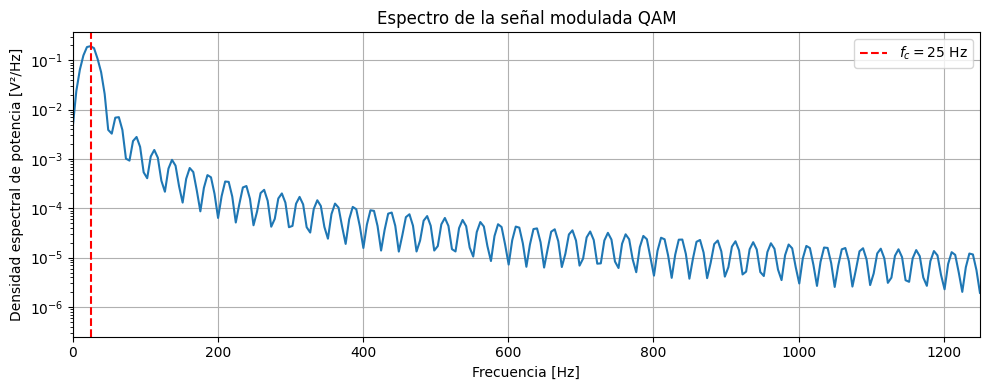

In [ ]:
from scipy.signal import welch

# Asegurar que s es un vector 1D
s = np.real(np.array(s).flatten())
s = np.array(s).flatten()

# Frecuencia de muestreo
Fs = 1 / Ts

# Welch
nperseg = 1024
freqs, Pxx = welch(s, fs=Fs, nperseg=nperseg, scaling='spectrum')

# Graficar
plt.figure(figsize=(10, 4))
plt.semilogy(freqs, Pxx)
plt.title("Espectro de la señal modulada QAM")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.grid(True)
plt.xlim([0, 50 * fc])
plt.tight_layout()
plt.axvline(fc, color='r', linestyle='--', label=f'$f_c = {fc}$ Hz')
plt.legend()
plt.show()


---
## **Conclusiones/Obervaciones**
**IMPORTANT**


1. Se puede observar la **discontinudad de fase** que es un **problema cómun de los esquemas sin memoria**.  
2. En este esquema sin memoria, PSK, vemos como el mudulador se comporta básicamente como un **mapeador**; le asigna formas de onda a la entrada de forma unívoca a los símbolos a transmitir.
2.   Esto no era muy visible aún en PAM por ejemplo, ya que la secuencia de símbolos se pasaba por un modulador producto (multiplicar la secuencia de símbolos/amplitudes por la portadora) de manera continua.
3. Para fines gráficos, seguimos haciendo que el tiempo de símbolo sea un multiplo entero del periodo de la protadora. Repetimos que esto **no es necesario**.


